# PCOS Ultrasound Dataset Understanding

This notebook focuses on understanding the PCOS ultrasound image dataset before model training.  
The goal is to inspect dataset structure, labels, image quality, class distribution, image dimensions, and possible data issues such as corrupted files or duplicates.

This step is important because the project guidelines require documented preprocessing, dataset description, visualizations, and proper handling of class imbalance before training the CNN model.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf

In [7]:
BASE_DIR = Path(r"data\PCOS\PCOS")

INFECTED_DIR = BASE_DIR / "infected"
NONINFECTED_DIR = BASE_DIR / "noninfected"

print("Base directory exists:", BASE_DIR.exists())
print("Infected directory exists:", INFECTED_DIR.exists())
print("Non-infected directory exists:", NONINFECTED_DIR.exists())

Base directory exists: True
Infected directory exists: True
Non-infected directory exists: True


## 2. Define Dataset Path

The dataset contains two classes:
- infected: ultrasound images showing PCOS cases
- noninfected: ultrasound images without PCOS

The path is checked before analysis to avoid loading errors.

In [8]:
image_paths = []
labels = []

for label_name in ["infected", "noninfected"]:
    folder_path = BASE_DIR / label_name
    
    for file_path in folder_path.iterdir():
        if file_path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            image_paths.append(str(file_path))
            labels.append(label_name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df.head()

,image_path,label
0,data\PCOS\PCOS\infected\image10000.jpg,infected
1,data\PCOS\PCOS\infected\image10001.jpg,infected
2,data\PCOS\PCOS\infected\image10002.jpg,infected
3,data\PCOS\PCOS\infected\image10003.jpg,infected
4,data\PCOS\PCOS\infected\image10004.jpg,infected


## 3. Create Dataset DataFrame

Each image path is stored with its corresponding label.  
This makes it easier to analyze, split, and load the dataset later using TensorFlow/Keras.

In [9]:
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass names:", df["label"].unique())

Dataset shape: (11784, 2)

Columns: ['image_path', 'label']

Missing values:
image_path    0
label         0
dtype: int64

Duplicate rows: 0

Class names: <StringArray>
['infected', 'noninfected']
Length: 2, dtype: str


## 4. Basic Data Quality Checks

Before training any model, we check:
- number of images
- missing values
- duplicate rows
- available classes

This helps ensure the dataset is clean and ready for preprocessing.

In [10]:
class_counts = df["label"].value_counts()
class_percentages = df["label"].value_counts(normalize=True) * 100

distribution_table = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percentages.round(2)
})

distribution_table

,count,percentage
label,,
infected,6784,57.57
noninfected,5000,42.43


## 5. Class Distribution

Class distribution is checked to detect imbalance.  
In medical classification, imbalance is important because a model may become biased toward the majority class.

According to the course material, accuracy alone is not enough for imbalanced datasets. Metrics such as precision, recall, F1-score, and balanced accuracy should also be used.

In [26]:
FIGURES_DIR = r"C:\Users\MHawa\OneDrive\Desktop\DL project\figures"

print("Figures will be saved to:", FIGURES_DIR)

Figures will be saved to: C:\Users\MHawa\OneDrive\Desktop\DL project\figures


## 6. Visualize Class Distribution

This chart shows the number of images in each class.  
It will be used later in the report to justify imbalance handling.

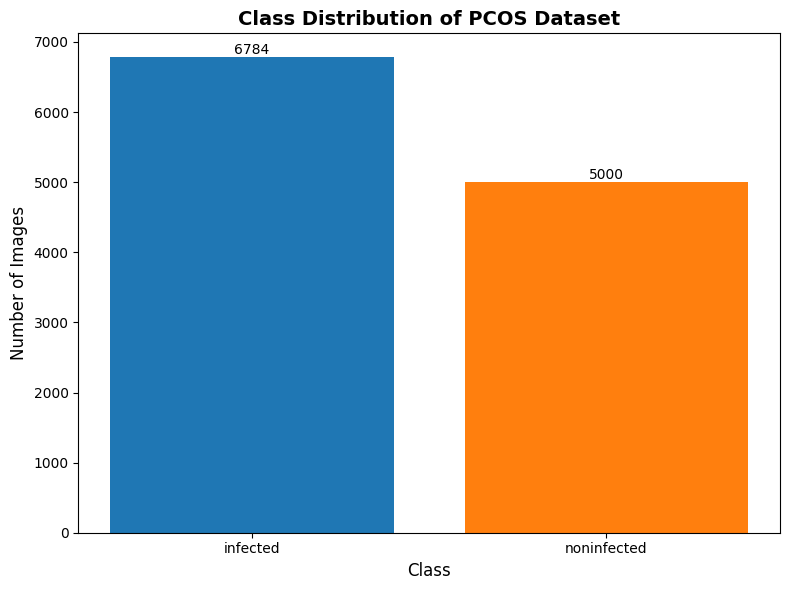

In [27]:
plt.figure(figsize=(8, 6))

bars = plt.bar(class_counts.index, class_counts.values, color=["#1f77b4", "#ff7f0e"])

plt.title("Class Distribution of PCOS Dataset", fontsize=14, fontweight="bold")
plt.xlabel("Class", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/class_distribution_bar.png", dpi=300)

plt.show()

## 7. Class Percentage Visualization

The pie chart shows the percentage of each class.  
This helps explain whether the dataset is balanced or imbalanced.

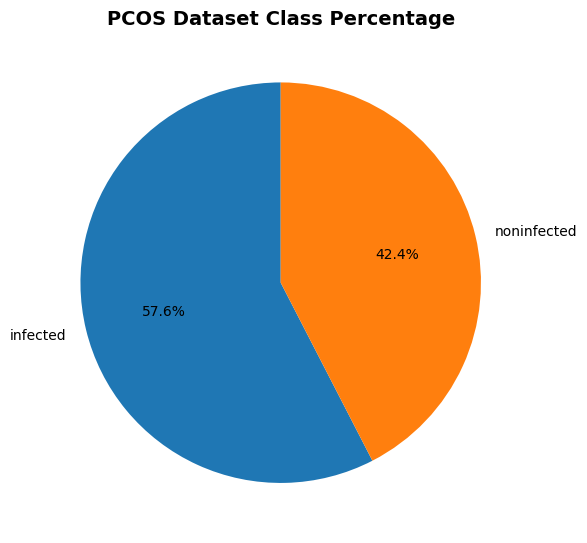

In [28]:
plt.figure(figsize=(6, 6))

plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#1f77b4", "#ff7f0e"]
)

plt.title("PCOS Dataset Class Percentage", fontsize=14, fontweight="bold")

plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/class_distribution_pie.png", dpi=300)

plt.show()

## 8. Check for Corrupted Images

Corrupted or unreadable images can stop the training process or introduce errors.  
We verify every image and remove corrupted files from the working dataframe.

In [14]:
valid_paths = []
valid_labels = []
corrupted_paths = []

for _, row in df.iterrows():
    try:
        with Image.open(row["image_path"]) as img:
            img.verify()
        valid_paths.append(row["image_path"])
        valid_labels.append(row["label"])
    except Exception:
        corrupted_paths.append(row["image_path"])

clean_df = pd.DataFrame({
    "image_path": valid_paths,
    "label": valid_labels
})

print("Original images:", len(df))
print("Valid images:", len(clean_df))
print("Corrupted images:", len(corrupted_paths))

Original images: 11784
Valid images: 11784
Corrupted images: 0


## 9. Image Dimension Analysis

CNN models require fixed-size input images.  
Therefore, we inspect the original image dimensions before resizing them in the preprocessing stage.

In [15]:
widths = []
heights = []

sample_for_size = clean_df["image_path"].tolist()

for image_path in sample_for_size:
    with Image.open(image_path) as img:
        w, h = img.size
        widths.append(w)
        heights.append(h)

clean_df["width"] = widths
clean_df["height"] = heights

clean_df[["width", "height"]].describe()

,width,height
count,11784.000000,11784.000000
mean,461.429311,412.297522
std,278.430532,242.569286
min,112.000000,108.000000
25%,270.000000,254.000000
50%,300.000000,300.000000
75%,630.000000,578.000000
max,984.000000,984.000000


## 10. Visualize Image Dimensions

This plot shows whether all images have similar dimensions or different sizes.  
If image sizes vary, resizing is required before training the CNN.

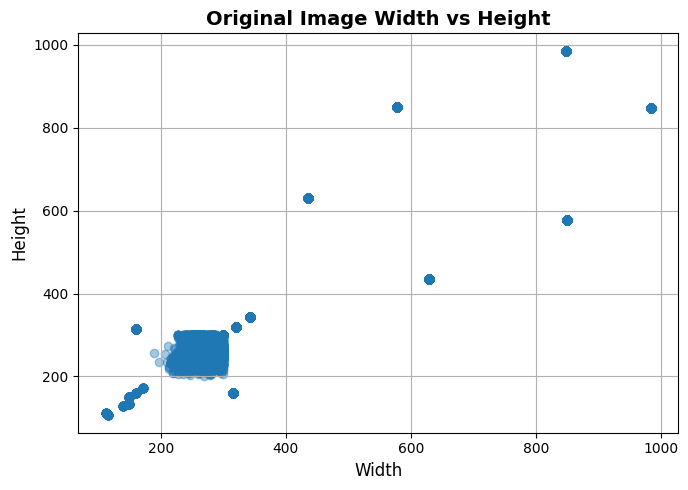

In [29]:
plt.figure(figsize=(7, 5))

plt.scatter(clean_df["width"], clean_df["height"], alpha=0.4)

plt.title("Original Image Width vs Height", fontsize=14, fontweight="bold")
plt.xlabel("Width", fontsize=12)
plt.ylabel("Height", fontsize=12)

plt.grid(True)

plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/image_size_scatter.png", dpi=300)

plt.show()

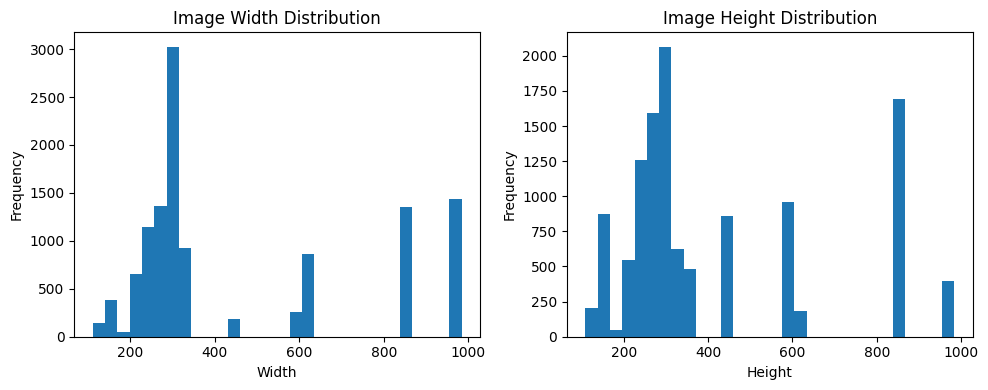

In [30]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(clean_df["width"], bins=30)
plt.title("Image Width Distribution")
plt.xlabel("Width")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(clean_df["height"], bins=30)
plt.title("Image Height Distribution")
plt.xlabel("Height")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/image_size_hist.png", dpi=300)

plt.show()

Figure: Distribution of image widths and heights. Most images are clustered within a specific range, confirming the need for resizing to a fixed input size.

## 11. Visual Inspection of Sample Images

Sample images from both classes are displayed to understand visual differences and confirm that the labels and folders are correct.

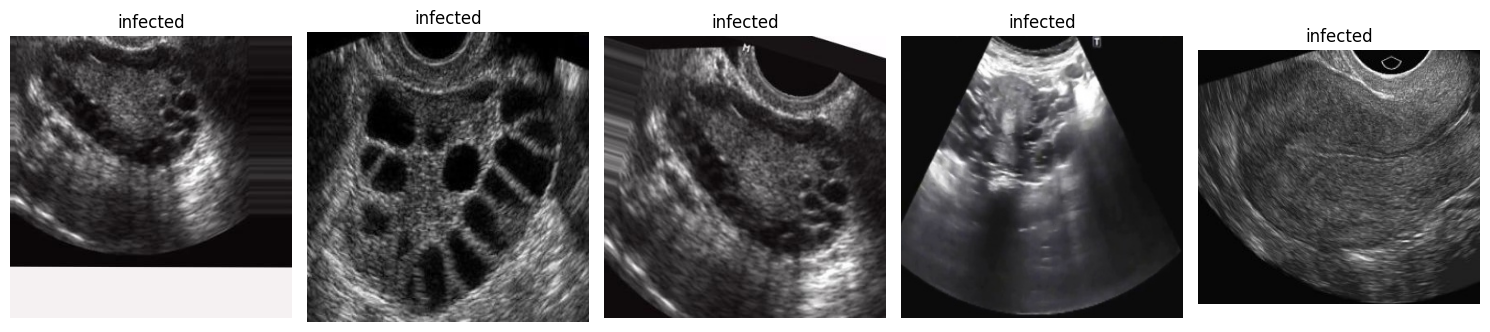

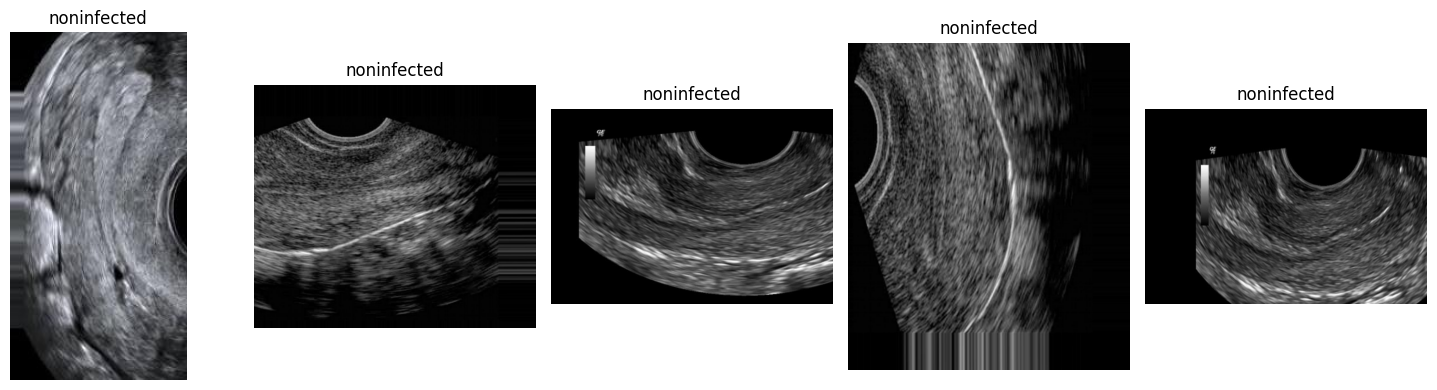

In [31]:
def save_sample_grid(dataframe, class_name, n=5):
    sample_df = dataframe[dataframe["label"] == class_name].sample(n=n, random_state=42)

    plt.figure(figsize=(15, 4))

    for i, image_path in enumerate(sample_df["image_path"]):
        img = Image.open(image_path).convert("RGB")

        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

    plt.tight_layout()

    plt.savefig(f"{FIGURES_DIR}/samples_{class_name}.png", dpi=300)

    plt.show()

save_sample_grid(clean_df, "infected", 5)
save_sample_grid(clean_df, "noninfected", 5)

## 12. Save Clean Dataset Metadata

The cleaned dataframe is saved as a CSV file.  
This file will be used in the next notebook for preprocessing, splitting, and CNN training.

In [19]:
OUTPUT_PATH = r"data/processed/clean_pcos_dataframe.csv"

clean_df.to_csv(OUTPUT_PATH, index=False)

print("Clean dataframe saved to:", OUTPUT_PATH)
print("Final clean dataset shape:", clean_df.shape)

Clean dataframe saved to: data/processed/clean_pcos_dataframe.csv
Final clean dataset shape: (11784, 4)


## Summary

In this notebook, we:
- loaded the PCOS ultrasound image dataset
- created a dataframe containing image paths and labels
- checked missing values and duplicates
- analyzed class distribution
- detected corrupted images
- inspected original image dimensions
- visualized sample images from both classes
- saved a clean metadata CSV file

The dataset shows a class imbalance between infected and noninfected images.  
This will be handled in the training stage using class weights and training-only augmentation, following the imbalance handling strategies discussed in the course.

The dataset contains 11,784 ultrasound images divided into two classes:
infected = 6,784 images (57.6%) and noninfected = 5,000 images (42.4%).

This shows a moderate class imbalance. Therefore, accuracy alone will not be enough to evaluate the model. During training, class weighting will be applied, and the final evaluation will include precision, recall, F1-score, AUC, and confusion matrix.

The image dimension plot shows that most images are concentrated around similar small dimensions, but there are some outlier image sizes. Therefore, all images will be resized to a fixed input size before feeding them into the CNN model.